**LEGACY** — dev notebook behind cluster_from_spikes.py (superseded bytry_tomato.py). Clusters peaks with SpikeInterface built-in methods(HDBSCAN/isosplit/graph-clustering), not Tomato. Kept for reference only.

In [40]:
pip install hdbscan

Note: you may need to restart the kernel to use updated packages.


In [41]:
import spikeinterface.full as si
import numpy as np
import os
import matplotlib.pyplot as plt
from spikeinterface.sortingcomponents.clustering import find_clusters_from_peaks
import hdbscan

## **Load Data and Spikes**

In [36]:
def load_data(file_path):
    if "imec" in file_path: 
        rec = si.read_spikeglx(file_path, stream_name='imec0.ap', load_sync_channel=False) 
        rec.get_probe().to_dataframe()
    else:
        rec = si.load(file_path, n_jobs = 6)
    return rec

##Load rec
bin_path = "/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed_slice_550_1270s"
animal = "6962"
frame_slice = [] # if want to slice, enter start and end time in s; if not, leave blank
rec = load_data(bin_path)
print(rec)

peaks_path = os.path.join(bin_path,"thresholding_peaks","peaks_combined2.npy")
detected_peaks = np.load(peaks_path)
detected_peaks = np.sort(detected_peaks, order='sample_index')
print(detected_peaks.shape)


BinaryFolderRecording: 355 channels - 30000.283521 Hz - 1 segments - 21,600,205 samples 
                       720.00s (12.00 minutes) - float16 dtype - 14.28 GiB
(2534389,)


In [ ]:
#check detected peak quality 
def plot_spike_local_areas(
    rec,
    peaks_sets,
    t_start,
    t_end,
    chan_start,
    chan_end,
    labels=None,
    save_path=None
):
    COLORS = [
        '#e6194b', '#4363d8', '#3cb44b', '#f58231', '#911eb4',
        '#42d4f4', '#f032e6', '#bfef45', '#fabed4', '#469990',
    ]

    if labels is None:
        labels = [f"Set {i+1}" for i in range(len(peaks_sets))]
    fs    = rec.sampling_frequency
    chans = rec.get_channel_ids()
    start_frame      = int(t_start * fs)
    end_frame        = int(t_end   * fs)
    chan_ids_to_plot = chans[chan_start:chan_end]

    traces = rec.get_traces(
        start_frame=start_frame,
        end_frame=end_frame,
        channel_ids=chan_ids_to_plot
    )

    num_chans      = len(chan_ids_to_plot)
    duration       = t_end - t_start
    
    plt.figure(figsize=(duration * 180, num_chans * 0.4))

    max_amp = np.max(np.abs(traces))
    spacing = max_amp * 1.5 if max_amp > 0 else 100
    offsets = np.arange(num_chans) * -spacing

    time_axis = np.linspace(t_start, t_end, traces.shape[0])

    # ---- Plot traces + threshold lines ----
    for i in range(traces.shape[1]):
        abs_chan_idx = chan_start + i
        plt.plot(time_axis, traces[:, i] + offsets[i], color='black', lw=0.5)

    # ---- Plot each set of peaks ----
    for set_idx, peaks in enumerate(peaks_sets):
        color   = COLORS[set_idx % len(COLORS)]
        label   = labels[set_idx]
        y_shift = set_idx * (spacing * 0.15)

        p_times  = peaks['sample_index'] / fs
        t_mask   = (p_times >= t_start) & (p_times <= t_end)
        c_mask   = (peaks['channel_index'] >= chan_start) & (peaks['channel_index'] < chan_end)
        filtered = peaks[t_mask & c_mask]

        if len(filtered) > 0:
            p_times_f      = filtered['sample_index'] / fs
            local_chan_idx = filtered['channel_index'] - chan_start
            p_pos          = filtered['amplitude'] + offsets[local_chan_idx] - y_shift
            plt.scatter(p_times_f, p_pos, color=color, s=10, zorder=3 + set_idx, label=label)

    # Labeling with Depths
    locations = rec.get_channel_locations()
    depths = locations[chan_start:chan_end, 1]
    depth_labels = [int(d) for d in depths]
    plt.yticks(offsets, depth_labels)

    plt.xlim(t_start, t_end)
    plt.xlabel("Time (s)")
    plt.ylabel("depth (um)")
    plt.grid(axis='x', alpha=0.1)
    plt.legend(loc='upper right', markerscale=2)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")

    plt.show()

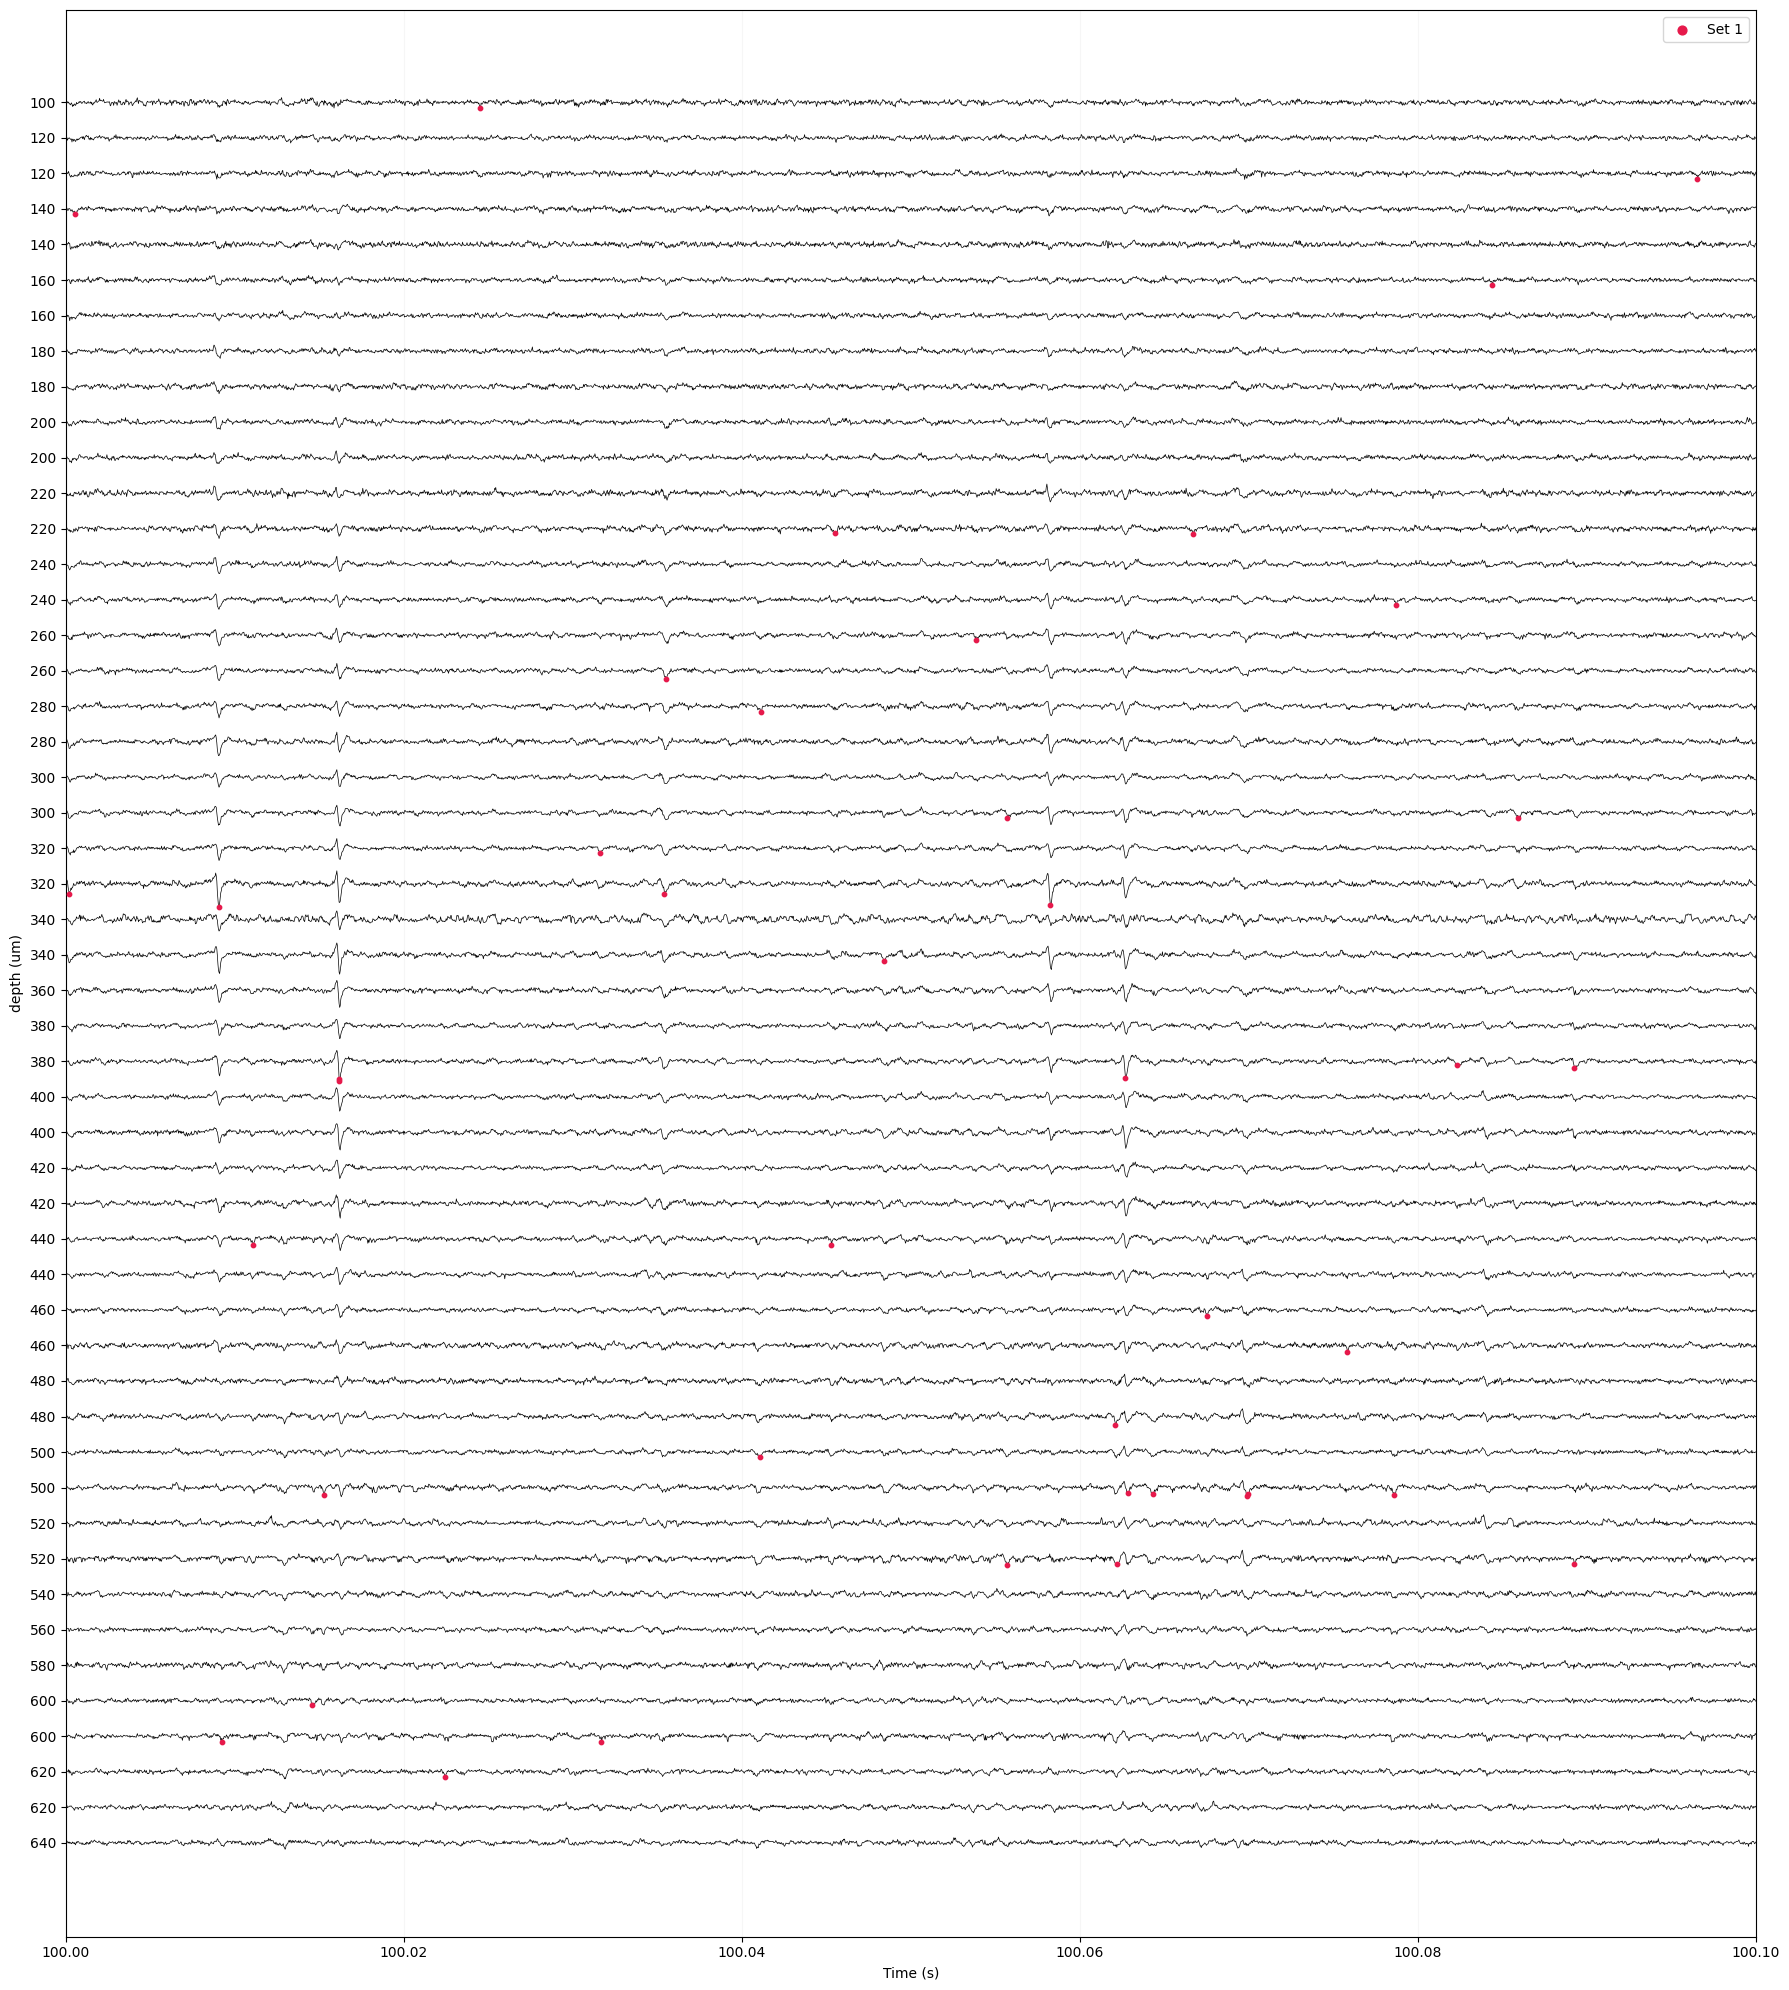

In [16]:
t_start = 100
chan_start = 10

plot_spike_local_areas(
    rec,
    peaks_sets=[detected_peaks],
    t_start = t_start,
    t_end = t_start+0.1,
    chan_start = chan_start,
    chan_end = chan_start+50,
    labels=None,
    save_path=None)

## **SI Clustering**

In [19]:
'''
availale methods: 
'iterative-hdbscan':
    used in spkyking-circus2. Performs local hdbscan clusetrings on svd waveforms features.
    1. local spatial grouping: spikes grouped by their estimated location; only spikes that are spatially nearby (within some radius on the probe) are considered together 
    2. feature extraction per group: waveforms are extracted and compressed (SVD)
    3. HDPSCAN on the local PCA features 
    4. "iterative": after first round of clustering, clusters that are too large or have internal variance are flagged as potentially merged units ==> these then re-clustered with HDBSCAN using tighter parameters ==> repeats until clusters stabilise or a stopping criterion is met 
    5. merging across spatial groups 

‘iterative-isosplit’method used in tridesclous2. This performs local isosplit clusetrings on
svd waveforms features.
‘hdbscan-positions’ : This performs a hdbscan clusetring based on the localizations of the spikes. This mimics the herdingspikes approach : make the clustering on spike position only but more flexible because more localization methods are availables.
‘random-projections’ : attempt to make the feature from waveforms with random projections instead of the good-old-school-pca.
‘graph-clustering’ : attempt to resolve the clusetring globally and not locally. This constructs a global but sparse distance matrix between all spikes. Can be slow. Then it performs ‘classical’ algos on graph (Louvain, Leiden or even HDBSCAN). Promising method but not as efficient as the ‘iterative-isosplit’ or ‘iterative-hdbscan’.

'''

'\navailale methods: \n'

In [26]:
print(detected_peaks[0])

(5, 351, -3.63671875, 0, 0.0)


In [43]:
job_kwargs = {
    "n_jobs": 6,  
    "chunk_duration": "1s", 
    "mp_context": "fork", 
    "pool_engine": "process", 
    "max_threads_per_worker": 1, 
    "progress_bar": True,
}

method_kwargs = {
    "peaks_svd": {
        "n_components": 6,
        "ms_before": 1,
        "ms_after": 1.5,
        "radius_um": 100.0,
    },
    "seed": 42,
    "split": {
        "split_radius_um": 100, #radius for neighbour channel mask 
        "recursive": True, #whether to split recursively
        "recursive_depth": 5,
        "method_kwargs": {
            "clusterer": {
                "method": "hdbscan",
                "min_cluster_size": 20,   # min cluster size
                "allow_single_cluster": True,
            },
            "n_pca_features": 3, # for splitting
        },
    },
    "merge_from_templates": {
        "similarity_thresh": 0.8,   
        "num_shifts": 3,
        "use_lags": True,
    },
    "merge_from_features": None,      # disabled
}

labels, peak_labels, extra_outputs = find_clusters_from_peaks(
    recording=rec,
    peaks=detected_peaks,
    method="iterative-hdbscan",
    method_kwargs=method_kwargs,
    extra_outputs=True,
    job_kwargs=job_kwargs
)


split_clusters with local_feature_clustering: 100%|██████████| 467/467 [00:36<00:00, 12.67it/s]


In [50]:
print(labels)
print(peak_labels.shape)

[  0   8  23  33  34  36  37  39  50  52  54  55  65  66  67  68  74  75
  76  77  89  91  93 100 105 107 109 111 113 122 135 150 152 157 158 163
 175 180 187 195 201 205 206 224 227 228 239 249 252 253 256 257 259 260
 261 263 264 265 266 267 268 269 270 271 273 276 277 279 280 281 283 285
 287 291 292 293 295 297 299 300 301 303 305 307 308 309 310 311 313 314
 315 316 317 318 319 321 323 324 325 326 328 329 330 331 332 333 334 335
 336 337 338 340 342 344 345 346 348 349 350 351 352 353 354 355 371 372
 374 376 380 381 383 385 387 395 396 397 401 402 403 410 411 417 439 445
 447 449 450 455 463 465]
(2534389,)


In [49]:
valid_mask = peak_labels >= 0
valid_peaks = detected_peaks[valid_mask]
valid_labels = peak_labels[valid_mask]
print(valid_peaks.shape)


(2495412,)


In [51]:
sorting = si.NumpySorting.from_samples_and_labels(
    samples_list=valid_peaks['sample_index'],
    labels_list=valid_labels,
    sampling_frequency=rec.get_sampling_frequency(),
)


In [54]:
analyzer = si.create_sorting_analyzer(
    sorting=sorting,
    recording=rec,
    format="binary_folder",   # or "binary_folder", path=<some_folder>
    folder=os.path.join(bin_path,"iterative-hdbscan_analyzer"),
    sparse=True,
    n_jobs = 10,
    chunk_duration = '1s',
    progress_bar = True
)


estimate_sparsity (workers: 10 processes): 100%|██████████| 721/721 [00:01<00:00, 460.26it/s]


In [55]:
# Required
print("computing templates...")
analyzer.compute("random_spikes", max_spikes_per_unit=1000)
analyzer.compute("waveforms", ms_before=1.0, ms_after=2.0, **job_kwargs)
analyzer.compute("templates")

# Recommended for quality in Phy
print("computing noise levels...")
analyzer.compute("noise_levels")
print("computing spike amplitudes...")
analyzer.compute("spike_amplitudes", **job_kwargs)
print("computing pcs")
analyzer.compute("principal_components", n_components=6, mode="by_channel_local", **job_kwargs)
print("computing template similarities...")
analyzer.compute("template_similarity")

# Optional but nice to have in Phy's ClusterView
print("computing quality metrics...")
analyzer.compute("quality_metrics", metric_names=["snr", "isi_violation", "presence_ratio", "amplitude_cutoff"])
print("computing template_metrics...")
analyzer.compute("template_metrics")

print("done!")


compute_waveforms (workers: 6 processes): 100%|██████████| 721/721 [00:28<00:00, 24.93it/s]
/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/numpy/_core/_methods.py:204: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)
Projecting waveforms: 100%|██████████| 150/150 [00:02<00:00, 51.98it/s]
/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/spikeinterface/qualitymetrics/misc_metrics.py:1059: UserWarning: Some units have too few spikes : amplitude_cutoff is set to NaN
  warnings.warn(f"Some units have too few spikes : amplitude_cutoff is set to NaN")


In [57]:
si.export_to_phy(
    sorting_analyzer=analyzer,
    output_folder=os.path.join(bin_path,"iterative-hdbscan_analyzer","export_to_phy"),
    compute_pc_features=True,     # enables PC features in Phy
    compute_amplitudes=True,       # enables amplitude view
    copy_binary=False,              # copies the .dat file alongside  
    remove_if_exists=False,
    verbose=True,
    job_kwargs=job_kwargs,
)


extract PCs (workers: 6 processes): 100%|██████████| 721/721 [07:59<00:00,  1.50it/s]


Run:
phy template-gui  /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed_slice_550_1270s/iterative-hdbscan_analyzer/export_to_phy/params.py
